# QRShield v2 — 5: Frequency Priors, Foundation Features and Robustness (companion study)

This notebook re-uses the cached features and saved models of notebooks 1–3 and asks six small, CPU-friendly research questions. Each one is taken from a *specific method or experiment* in recent papers of Prof. Pingping Zhang's group (Dalian University of Technology) and applied to QR tamper detection:

| # | Source in the papers | Question asked here |
|---|---|---|
| RQ1 | HFP-SAM §III-A/B: Haar-wavelet high-frequency map, sliding windows, top-k window selection | Does a **local** wavelet prior (top-k high-frequency windows) detect local tampering better than the **global** FFT spectrum used in notebooks 1–2, especially on `module_corruption`? |
| RQ2 | HFP-SAM Table IV/V (window size, number of windows; random vs global vs frequency-selected) and §F (wavelet vs Canny edges) | Does *frequency-based window selection* matter? Wavelet vs Canny? Sensitivity to window size and k? |
| RQ3 | HFP-SAM §E (Gaussian and speckle noise stress test) | How do wavelet, FFT, DINOv2 and EfficientNet cues degrade under noise? |
| RQ4 | HFP-SAM Fig. 5 (pairwise dataset distances with Wasserstein-1 and MMD-RBF) | How large are the distribution shifts between benign styles, camera layer and tamper families? Does shift predict transfer failure? |
| RQ5 | SFMFusion / ISFM introductions: frequency should *interact* with spatial features instead of simple serial/parallel fusion | Does frequency-guided gated fusion of DINOv2 + frequency cues beat plain concatenation, especially on unseen families (LOFO)? |
| RQ6 | HFP-SAM §I (zero-shot / cross-domain evaluation) | Do features transfer from clean to camera images, and from plain benign to styled/logo benign codes? |

**What was read.** HFP-SAM (arXiv 2603.12708) was read in full. For SFMFusion (arXiv 2511.06593) and ISFM (arXiv 2602.04405) only the abstracts and introductions were read, so RQ5 is a *simplified analogue* of the interaction idea, not a reimplementation.

**Deviations from the papers (stated up front).** Windows are non-overlapping; the high-frequency map averages the *magnitudes* of the three sub-bands (signed averaging cancels); the classifier is gradient boosting / a small network on frozen features, not an end-to-end segmentation model; distances use an unbiased RBF-MMD with the median heuristic and a *sliced* Wasserstein-1. No result here should be described as reproducing the papers.

**Run order.** Notebooks 1 and 2 first (this notebook needs the cached `freq` and `dino_small` features; the DINOv2 configuration file from notebook 2 is used if present). Notebook 3 is needed for RQ3 (EfficientNet under noise). Everything is resumable. Default is the full study; `SMOKE = True` gives a quick check.

In [ ]:
# ── Common setup (identical in all four notebooks) ───────────────────────────
import os, gc, sys, json, time, glob, shutil, subprocess, warnings, zipfile
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # not running on Colab

SMOKE = False         # False = FULL study (default). True = quick pipeline check on a small slice (separate output folders).
SMOKE_ROWS = 3000     # number of manifest rows used in smoke mode
SEEDS = [0, 1, 2]
IMG = 224
FAMILIES = ['sticker_overlay', 'module_corruption', 'patch_overlay', 'logo_manipulation', 'occlusion_warp']
V1_FAMILIES = ['module_corruption', 'patch_overlay']        # the two tamper families v1 was trained on
METHODS = ['v1', 'aug', 'v2', 'freq', 'dino']

ROOT = Path(os.environ.get('QR_ROOT', '/content/drive/MyDrive/qrshield_v2'))
D = Path(os.environ.get('QR_DATA', '/content/qrshield_v2_data'))          # local copy of the dataset
ZIPS = Path(os.environ.get('QR_ZIPS', '/content/zips'))
OUT = ROOT / ('v2_eval_smoke' if SMOKE else 'v2_eval')
FEA, RES, MOD, TAB = (OUT / n for n in ('feats', 'results', 'models', 'tables'))
for p in (FEA, RES, MOD, TAB):
    p.mkdir(parents=True, exist_ok=True)
print('MODE:', 'SMOKE (small slice, NOT the real study)' if SMOKE else 'FULL study', f'| outputs -> {OUT}')

Mounted at /content/drive
MODE: FULL study | outputs -> /content/drive/MyDrive/qrshield_v2/v2_eval


In [ ]:
# ── This study writes to its own folders; the main study's results stay untouched ──
RES = OUT / 'study5_results'
TAB = OUT / 'study5_tables'
for p in (RES, TAB):
    p.mkdir(parents=True, exist_ok=True)
import tensorflow as tf
for g in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(g, True)
print('study-5 results ->', RES)

study-5 results -> /content/drive/MyDrive/qrshield_v2/v2_eval/study5_results


In [ ]:
# ── Data: copy shards to the local disk, extract, merge the manifest ─────────
def prepare_data():
    if (D / '.done').exists():
        return
    D.mkdir(parents=True, exist_ok=True)
    ZIPS.mkdir(parents=True, exist_ok=True)
    src = sorted(glob.glob(str(ROOT / 'shard500' / 'shard_*.zip')))
    assert src, f'No shard_*.zip found in {ROOT / "shard500"}'
    for z in src:                                   # bulk copy Drive -> local disk (fast), verified by file size
        dst = ZIPS / Path(z).name
        size = os.path.getsize(z)
        for attempt in range(3):
            if dst.exists() and dst.stat().st_size == size:
                break
            shutil.copy(z, dst)                     # (re)copy; a half-copied file is never trusted
        else:
            raise RuntimeError(f'{Path(z).name}: copy incomplete after 3 tries (Drive {size} bytes, local {dst.stat().st_size}). '
                               'If Drive itself shows a smaller/odd size, this shard is broken: delete it on Drive and rebuild it.')
    zips = sorted(glob.glob(str(ZIPS / 'shard_*.zip')))
    tops = set()                                    # create the target folders first: two parallel unzips
    for z in zips:                                  # must never race to create the same directory
        with zipfile.ZipFile(z) as zz:
            tops |= {n.split('/')[0] for n in zz.namelist() if '/' in n}
    for t in tops:
        (D / t).mkdir(parents=True, exist_ok=True)
    def unz(z):
        for attempt in range(2):
            r = subprocess.run(['unzip', '-q', '-o', z, '-x', 'manifest.csv', '-d', str(D)], capture_output=True, text=True)
            if r.returncode in (0, 1):              # 1 = harmless warning
                return
        raise RuntimeError(f'unzip failed for {Path(z).name} (code {r.returncode}): {(r.stderr or r.stdout).strip()}')
    with ThreadPoolExecutor(2) as ex:
        list(ex.map(unz, zips))
    parts = []
    for z in zips:
        with zipfile.ZipFile(z) as zz:
            parts.append(pd.read_csv(zz.open('manifest.csv'), keep_default_na=False))
    merged = pd.concat(parts, ignore_index=True)
    merged.to_csv(D / 'manifest.csv', index=False)
    shutil.rmtree(ZIPS, ignore_errors=True)         # free local disk
    (D / '.done').write_text('ok')
    print('shards:', len(zips), '| manifest rows:', len(merged))

prepare_data()

man = pd.read_csv(D / 'manifest.csv', keep_default_na=False)
if SMOKE:
    man = man.iloc[:SMOKE_ROWS].copy()
need = ['image', 'set', 'split', 'base_id', 'cls', 'family', 'camera']
miss = [c for c in need if c not in man.columns]
assert not miss, f'manifest is missing columns {miss}; found {man.columns.tolist()}'

man['fp'] = str(D) + '/' + man['image'].astype(str)
man['cls_'] = man['cls'].astype(str)
man['label'] = (~man.cls_.str.startswith('benign')).astype(int)
man['fam'] = np.where(man.label == 1, man.cls_.str.replace('^tamper_', '', regex=True), 'benign')
man['base'] = man['base_id'].astype(str)
man['split_'] = man['split'].astype(str)
man['set_'] = man['set'].astype(str)
man['has_cam'] = man['camera'].astype(str).str.strip().str.lower().eq('true')
man['fidx'] = np.arange(len(man))

missing = [p for p in man.fp if not os.path.exists(p)]
assert not missing, f'{len(missing)} image files missing, e.g. {missing[:3]}'
assert set(man.fam.unique()) - {'benign'} == set(FAMILIES), man.fam.unique()

main = man[man.set_ == 'main']
tr = main[main.split_ == 'train']
va = main[main.split_ == 'val']
te = main[main.split_ == 'test']
cam = man[man.set_ == 'camera_bench']
# integrity checks: group split (no base QR in two splits); benchmark only from test bases
assert not set(tr.base) & set(te.base) and not set(tr.base) & set(va.base) and not set(va.base) & set(te.base)
assert not set(cam.base) & set(tr.base) and not set(cam.base) & set(va.base)
share = main.groupby('label').has_cam.mean()
assert 0.3 < share.min() and share.max() < 0.5, f'camera-layer share should be ~0.4 for both labels: {share.to_dict()}'
print(f'rows={len(man)} | main={len(main)} (train {len(tr)} / val {len(va)} / test {len(te)}) | camera_bench={len(cam)}')
print('camera-layer share by label:', share.round(3).to_dict())
if not SMOKE:   # safeguard: the full study must see the whole dataset
    assert len(man) > 60000 and len(tr) > 35000, f'FULL mode expects ~66,000 rows / ~42,000 train images, got {len(man)} / {len(tr)}. Check that all 24 shards are in {ROOT / "shard500"}.'

shards: 24 | manifest rows: 66083
rows=66083 | main=60000 (train 41958 / val 5810 / test 12232) | camera_bench=6083
camera-layer share by label: {0: 0.404, 1: 0.401}


In [ ]:
# ── Metrics and result storage ────────────────────────────────────────────────
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, balanced_accuracy_score

def pick_th(y, p):
    """Decision threshold chosen on the validation set (maximises balanced accuracy)."""
    ths = np.linspace(0.02, 0.98, 97)
    return float(ths[int(np.argmax([balanced_accuracy_score(y, p > t) for t in ths]))])

def m_row(y, p, th):
    y = np.asarray(y)
    return dict(n=int(len(y)), acc=accuracy_score(y, p > th), bal_acc=balanced_accuracy_score(y, p > th),
                auroc=roc_auc_score(y, p) if len(set(y)) > 1 else np.nan,
                f1=f1_score(y, p > th, zero_division=0), acc05=accuracy_score(y, p > 0.5))

def family_records(df, p, th, test, meta):
    """One record for ALL images plus one per tamper family. For a family, the benign images are
    subsampled (fixed seed) to the same size, so accuracy / F1 are not distorted by class imbalance."""
    df = df.reset_index(drop=True)
    ben = np.where(df.label.values == 0)[0]
    groups = [('ALL', np.arange(len(df)))]
    for f in sorted(df.fam[df.label == 1].unique()):
        idx = np.where(df.fam.values == f)[0]
        b = np.random.default_rng(123).choice(ben, size=min(len(idx), len(ben)), replace=False)
        groups.append((f, np.concatenate([b, idx])))
    return [dict(meta, test=test, family=f, th=th, **m_row(df.label.values[i], p[i], th)) for f, i in groups]

def rpath(key): return RES / f'{key}.json'
def done(key): return rpath(key).exists()

def finish(key, score, th, tests, meta):
    recs = []
    for name, df in tests.items():
        recs += family_records(df, score(df), th, name, meta)
    tmp = RES / f'{key}.tmp'
    json.dump(recs, open(tmp, 'w'))
    os.replace(tmp, rpath(key))                      # atomic: a half-written result never counts as done

def tests_final():
    return {'indist': te, 'camera_bench': cam}

def tests_lofo(held):
    return {'indist_heldout': pd.concat([te[te.label == 0], te[te.fam == held]]),
            'camera_heldout': pd.concat([cam[cam.label == 0], cam[cam.fam == held]])}

def v1_subset(df):
    """v1-style training data: plain benign + the two v1 tamper families, no camera layer."""
    return df[(df.fam.isin(V1_FAMILIES) | (df.cls_ == 'benign_plain')) & ~df.has_cam]

def show_status():
    names = [f.stem for f in RES.glob('*__s*.json')]
    print('finished jobs per method:', pd.Series([n.split('__')[0] for n in names]).value_counts().to_dict())

## Wavelet-window and Canny features (RQ1, RQ2)
Extraction is chunked and resumable. Equivalence of the PIL-based FFT function with the stored notebook-1 features is asserted in the next cell.

In [ ]:
# ── Chunked, resumable feature store (same format as notebook 1) ─────────────
from PIL import Image
import cv2
CHUNK = 4096

def extract_chunked(tag, paths, fn, dtype):
    d = FEA / tag
    d.mkdir(parents=True, exist_ok=True)
    meta = dict(n=len(paths), first=paths[0], last=paths[-1])
    mp = d / 'meta.json'
    if mp.exists():
        assert json.load(open(mp)) == meta, f'Manifest changed since {d} was written; delete that folder.'
    else:
        json.dump(meta, open(mp, 'w'))
    n_chunks = (len(paths) + CHUNK - 1) // CHUNK
    for i in range(n_chunks):
        f = d / f'part_{i:04d}.npy'
        if f.exists():
            continue
        t0 = time.time()
        arr = fn(paths[i * CHUNK:(i + 1) * CHUNK]).astype(dtype)
        tmp = d / f'part_{i:04d}.tmp.npy'
        np.save(tmp, arr)
        os.replace(tmp, f)
        print(f'{tag}: chunk {i + 1}/{n_chunks} done ({time.time() - t0:.0f}s)', flush=True)

def load_feats(tag):
    d = FEA / tag
    return np.concatenate([np.load(f) for f in sorted(d.glob('part_*.npy')) if '.tmp' not in f.name])

In [ ]:
# ── RQ1/RQ2: wavelet-window and Canny-window features ────────────────────────
# HFP-SAM: Haar DWT -> LL, LH, HL, HH; frequency map M^h = mean of the three high-frequency sub-bands;
# window-wise average of M^h; the top-k windows are the "frequency prior regions".
WS_LIST = [4, 8, 16]    # window size on the 112x112 high-frequency map  (= 8, 16, 32 px of the 224x224 image)
KMAX = 20
RAW_WS = 8              # raw window responses are stored for this size (random / global / top-k ablation)

def haar_bands(a):
    a00, a01, a10, a11 = a[0::2, 0::2], a[0::2, 1::2], a[1::2, 0::2], a[1::2, 1::2]
    return ((a00 + a01 + a10 + a11) / 2, (a00 + a01 - a10 - a11) / 2,
            (a00 - a01 + a10 - a11) / 2, (a00 - a01 - a10 + a11) / 2)      # LL, LH, HL, HH

def win_means(m, ws):
    n = m.shape[0] // ws
    return m[:n * ws, :n * ws].reshape(n, ws, n, ws).mean(axis=(1, 3)).ravel()

def win_stats(w):
    s = np.sort(w)[::-1]
    return np.concatenate([s[:KMAX], [w.mean(), w.std(), s[0] / (np.median(w) + 1e-6)]])    # top-20 + 3 stats = 23

def wavelet_feat_pil(im):
    a = np.asarray(im.convert('L').resize((IMG, IMG), Image.BILINEAR), np.float32) / 255.
    ll, lh, hl, hh = haar_bands(a)
    m = (np.abs(lh) + np.abs(hl) + np.abs(hh)) / 3                           # frequency map M^h
    raw = win_means(m, RAW_WS)                                               # 196 raw window responses
    parts = [raw] + [win_stats(win_means(m, ws)) for ws in WS_LIST]          # + 3 x 23
    glob = [np.log(np.abs(b).mean() + 1e-6) for b in (lh, hl, hh)] + [ll.std()]
    return np.concatenate(parts + [glob]).astype(np.float32)                 # 196 + 69 + 4 = 269

def canny_feat_pil(im):
    g = np.asarray(im.convert('L').resize((IMG, IMG), Image.BILINEAR), np.uint8)
    e = (cv2.Canny(g, 100, 200) > 0).astype(np.float32)
    parts = [win_stats(win_means(e, w)) for w in (8, 16, 32)]                 # windows of 8/16/32 px
    return np.concatenate(parts + [[e.mean()]]).astype(np.float32)           # 69 + 1 = 70

def freq_feat_pil(im):
    """Identical to the notebook-1 FFT features, but takes a PIL image (needed for the noise test)."""
    a = np.asarray(im.convert('L').resize((IMG, IMG), Image.BILINEAR), np.float32) / 255.
    a = (a - a.mean()) * WIN
    mag = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(a)))).ravel()
    prof = np.bincount(RBIN, mag, minlength=NB) / RCNT
    ah = np.bincount(ABIN[HI], mag[HI], minlength=12) / np.maximum(np.bincount(ABIN[HI], minlength=12), 1)
    al = np.bincount(ABIN[LO], mag[LO], minlength=12) / np.maximum(np.bincount(ABIN[LO], minlength=12), 1)
    pw = np.expm1(mag) ** 2
    return np.concatenate([prof, ah, al, [pw[HI].sum() / (pw.sum() + 1e-9)]]).astype(np.float32)

_yy, _xx = np.mgrid[:IMG, :IMG]
_r = np.hypot(_yy - IMG // 2, _xx - IMG // 2)
_theta = np.mod(np.arctan2(_yy - IMG // 2, _xx - IMG // 2), np.pi)
NB = 56
RBIN = np.minimum((_r / 2).astype(int), NB - 1).ravel()
RCNT = np.maximum(np.bincount(RBIN, minlength=NB), 1)
ABIN = (_theta / np.pi * 12).astype(int).clip(0, 11).ravel()
HI, LO = (_r >= 56).ravel(), ((_r >= 8) & (_r < 40)).ravel()
WIN = np.outer(np.hanning(IMG), np.hanning(IMG)).astype(np.float32)

def _extract(fn):
    def run(paths):
        with ThreadPoolExecutor(os.cpu_count() or 2) as ex:
            return np.stack(list(ex.map(lambda p: fn(Image.open(p)), paths)))
    return run

paths = list(man.fp)
t0 = time.time()
extract_chunked('wavelet_v1', paths, _extract(wavelet_feat_pil), np.float32)
extract_chunked('canny_v1', paths, _extract(canny_feat_pil), np.float32)
print(f'wavelet + canny features ready ({(time.time() - t0) / 60:.1f} min)')

wavelet_v1: chunk 1/17 done (9s)
wavelet_v1: chunk 2/17 done (10s)
wavelet_v1: chunk 3/17 done (9s)
wavelet_v1: chunk 4/17 done (9s)
wavelet_v1: chunk 5/17 done (9s)
wavelet_v1: chunk 6/17 done (10s)
wavelet_v1: chunk 7/17 done (10s)
wavelet_v1: chunk 8/17 done (9s)
wavelet_v1: chunk 9/17 done (9s)
wavelet_v1: chunk 10/17 done (9s)
wavelet_v1: chunk 11/17 done (10s)
wavelet_v1: chunk 12/17 done (9s)
wavelet_v1: chunk 13/17 done (9s)
wavelet_v1: chunk 14/17 done (9s)
wavelet_v1: chunk 15/17 done (9s)
wavelet_v1: chunk 16/17 done (10s)
wavelet_v1: chunk 17/17 done (1s)
canny_v1: chunk 1/17 done (8s)
canny_v1: chunk 2/17 done (7s)
canny_v1: chunk 3/17 done (8s)
canny_v1: chunk 4/17 done (8s)
canny_v1: chunk 5/17 done (7s)
canny_v1: chunk 6/17 done (8s)
canny_v1: chunk 7/17 done (7s)
canny_v1: chunk 8/17 done (8s)
canny_v1: chunk 9/17 done (8s)
canny_v1: chunk 10/17 done (8s)
canny_v1: chunk 11/17 done (7s)
canny_v1: chunk 12/17 done (7s)
canny_v1: chunk 13/17 done (8s)
canny_v1: chunk 14/

## Load features and define the compared variants

In [ ]:
# ── Load all feature sets and define the compared variants ────────────────────
FREQ_X = load_feats('freq')                       # notebook 1: global FFT features (81-d)
_dino = load_feats('dino_small')                  # notebook 1: [CLS | mean | max | std] DINOv2 tokens
WAV_X, CAN_X = load_feats('wavelet_v1'), load_feats('canny_v1')
assert len(FREQ_X) == len(_dino) == len(WAV_X) == len(CAN_X) == len(man), 'feature rows must match the manifest'

# equivalence check: the PIL-based FFT function must reproduce the stored notebook-1 features
chk = np.stack([freq_feat_pil(Image.open(p)) for p in man.fp.values[:20]])
assert np.allclose(chk, FREQ_X[:20], atol=1e-3), 'freq_feat_pil does not match the stored FFT features'

cfg_file = OUT / 'dino_config.json'
DINO_SET = json.load(open(cfg_file))['feature_set'] if cfg_file.exists() else 'cls+mean+max'
BLK = _dino.shape[1] // 4
FEATURE_SETS = {'cls+mean': [0, 1], 'cls+mean+max': [0, 1, 2], 'all4': [0, 1, 2, 3]}
DCOLS = np.concatenate([np.arange(b * BLK, (b + 1) * BLK) for b in FEATURE_SETS[DINO_SET]])
DINO_X = _dino[:, DCOLS].astype(np.float32)
print('DINOv2 feature set:', DINO_SET, DINO_X.shape)

GLOB = list(range(265, 269))
def wcols(ws, k):                                  # top-k window responses + 3 window stats for window size ws
    b = 196 + 23 * WS_LIST.index(ws)
    return list(range(b, b + k)) + list(range(b + KMAX, b + KMAX + 3))
RAND_IDX = np.random.default_rng(0).choice(196, 10, replace=False)
WMULTI = [c for ws in WS_LIST for c in wcols(ws, 20)] + GLOB
CAN_TOPK = list(range(23, 33)) + list(range(43, 46)) + [69]          # 16-px windows, k=10, + global edge density

SETS = {                                           # main comparison (final + LOFO)
    'fft_global': FREQ_X,                                            # notebooks 1-2
    'wav_topk':   WAV_X[:, wcols(8, 10) + GLOB],                     # HFP-SAM style: top-10 frequency windows
    'wav_multi':  WAV_X[:, WMULTI],                                  # three window sizes, k=20
    'wav_random': WAV_X[:, list(RAND_IDX) + GLOB],                   # 10 random windows (no frequency selection)
    'wav_global': WAV_X[:, [196 + 23 + KMAX + j for j in range(3)] + GLOB],   # statistics over ALL windows (no selection)
    'canny_topk': CAN_X[:, CAN_TOPK],                                # Canny edge density instead of wavelet
    'dino_ref':   DINO_X,                                            # frozen DINOv2 reference
}
ABLATION = {                                       # window size / k sensitivity (final only)
    'abl_k5':   WAV_X[:, wcols(8, 5) + GLOB],  'abl_k20':  WAV_X[:, wcols(8, 20) + GLOB],
    'abl_ws4':  WAV_X[:, wcols(4, 10) + GLOB], 'abl_ws16': WAV_X[:, wcols(16, 10) + GLOB],
}
ALLSETS = {**SETS, **ABLATION}
print({k: v.shape[1] for k, v in ALLSETS.items()})

DINOv2 feature set: cls+mean (66083, 768)
{'fft_global': 81, 'wav_topk': 17, 'wav_multi': 73, 'wav_random': 14, 'wav_global': 7, 'canny_topk': 14, 'dino_ref': 768, 'abl_k5': 12, 'abl_k20': 27, 'abl_ws4': 17, 'abl_ws16': 17}


## RQ1 / RQ2: local wavelet prior vs global FFT; window selection; wavelet vs Canny
Same classifier and protocol for every feature set (final model + leave-one-family-out, 3 seeds).

In [ ]:
# ── RQ1/RQ2 jobs: same classifier, same protocol (final + LOFO), 3 seeds ─────
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def make_clf2(sid, seed):
    if sid == 'dino_ref':
        return make_pipeline(StandardScaler(), MLPClassifier((256,), early_stopping=True, max_iter=100, random_state=seed))
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, early_stopping=True, random_state=seed)

def st_job(sid, setting, seed):
    key = f'{sid}__{setting}__s{seed}'
    if done(key):
        return
    held = setting[5:] if setting.startswith('lofo_') else None
    X = ALLSETS[sid]
    tr_, va_ = (tr, va) if held is None else (tr[tr.fam != held], va[va.fam != held])
    clf = make_clf2(sid, seed).fit(X[tr_.fidx.values], tr_.label.values)
    score = lambda df: clf.predict_proba(X[df.fidx.values])[:, 1]
    th = pick_th(va_.label.values, score(va_))
    tests = tests_final() if held is None else tests_lofo(held)
    finish(key, score, th, tests, dict(method=sid, setting=setting, seed=seed))

def study_jobs():
    J = []
    for seed in SEEDS:
        for sid in SETS:
            J += [(sid, s, seed) for s in ['final'] + [f'lofo_{f}' for f in FAMILIES]]
        J += [(sid, 'final', seed) for sid in ABLATION]
    return J

def run_study(max_minutes=120):
    t0 = time.time()
    todo = [j for j in study_jobs() if not done(f'{j[0]}__{j[1]}__s{j[2]}')]
    print(f'{len(todo)} of {len(study_jobs())} jobs remaining')
    for j in todo:
        if (time.time() - t0) / 60 > max_minutes:
            print('time budget reached; run this cell again to continue'); return
        t1 = time.time(); st_job(*j)
        print(f'  done {j} ({(time.time() - t1) / 60:.1f} min)', flush=True)
    print('RQ1/RQ2 queue complete')

run_study()

138 of 138 jobs remaining
  done ('fft_global', 'final', 0) (0.0 min)
  done ('fft_global', 'lofo_sticker_overlay', 0) (0.0 min)
  done ('fft_global', 'lofo_module_corruption', 0) (0.0 min)
  done ('fft_global', 'lofo_patch_overlay', 0) (0.0 min)
  done ('fft_global', 'lofo_logo_manipulation', 0) (0.0 min)
  done ('fft_global', 'lofo_occlusion_warp', 0) (0.0 min)
  done ('wav_topk', 'final', 0) (0.0 min)
  done ('wav_topk', 'lofo_sticker_overlay', 0) (0.0 min)
  done ('wav_topk', 'lofo_module_corruption', 0) (0.0 min)
  done ('wav_topk', 'lofo_patch_overlay', 0) (0.0 min)
  done ('wav_topk', 'lofo_logo_manipulation', 0) (0.0 min)
  done ('wav_topk', 'lofo_occlusion_warp', 0) (0.0 min)
  done ('wav_multi', 'final', 0) (0.0 min)
  done ('wav_multi', 'lofo_sticker_overlay', 0) (0.0 min)
  done ('wav_multi', 'lofo_module_corruption', 0) (0.0 min)
  done ('wav_multi', 'lofo_patch_overlay', 0) (0.0 min)
  done ('wav_multi', 'lofo_logo_manipulation', 0) (0.0 min)
  done ('wav_multi', 'lofo_oc

## RQ5: frequency-guided fusion vs concatenation

In [ ]:
# ── RQ5: frequency-guided (interactive) fusion vs plain concatenation ─────────
# Simplified analogue of the ISFM idea: frequency cues GUIDE the spatial (DINOv2) features through a gate,
# instead of being concatenated next to them (serial/parallel fusion). Not a reimplementation of ISFM.
FQ = np.concatenate([FREQ_X, WAV_X, CAN_X], axis=1).astype(np.float32)     # all frequency-domain cues
EP_FUS = 2 if SMOKE else 12

class BestW(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__(); self.best, self.w = -1, None
    def on_epoch_end(self, epoch, logs=None):
        v = (logs or {}).get('val_auc', -1)
        if v > self.best:
            self.best, self.w = v, self.model.get_weights()
    def on_train_end(self, logs=None):
        if self.w is not None:
            self.model.set_weights(self.w)

def build_fusion(mode, d_dino, d_freq, hid=256):
    L = tf.keras.layers
    xd, xf = tf.keras.Input((d_dino,)), tf.keras.Input((d_freq,))
    if mode == 'dino':
        h = L.Dense(hid, activation='relu')(xd)
        # Keep xf connected to avoid Keras ValueError
        dummy = L.Lambda(lambda x: 0.0 * tf.reduce_sum(x, axis=1, keepdims=True))(xf)
        h = L.Add()([h, dummy])
    elif mode == 'freq':
        h = L.Dense(hid, activation='relu')(xf)
        # Keep xd connected to avoid Keras ValueError
        dummy = L.Lambda(lambda x: 0.0 * tf.reduce_sum(x, axis=1, keepdims=True))(xd)
        h = L.Add()([h, dummy])
    elif mode == 'concat':                                   # serial/parallel fusion
        h = L.Dense(hid, activation='relu')(L.Concatenate()([xd, xf]))
    else:                                                    # 'gated': frequency guides the spatial features
        gate = L.Dense(hid, activation='sigmoid')(L.Dense(64, activation='relu')(xf))
        h = L.Multiply()([L.Dense(hid, activation='relu')(xd), gate])
    h = L.Dropout(0.3)(h)
    return tf.keras.Model([xd, xf], L.Dense(1, activation='sigmoid')(h))

def fusion_job(mode, setting, seed):
    key = f'fus_{mode}__{setting}__s{seed}'
    if done(key):
        return
    held = setting[5:] if setting.startswith('lofo_') else None
    tr_, va_ = (tr, va) if held is None else (tr[tr.fam != held], va[va.fam != held])
    tf.keras.utils.set_random_seed(seed)
    md, sd = DINO_X[tr_.fidx.values].mean(0), DINO_X[tr_.fidx.values].std(0) + 1e-6
    mf, sf = FQ[tr_.fidx.values].mean(0), FQ[tr_.fidx.values].std(0) + 1e-6
    prep = lambda df: [(DINO_X[df.fidx.values] - md) / sd, (FQ[df.fidx.values] - mf) / sf]
    model = build_fusion(mode, DINO_X.shape[1], FQ.shape[1])
    model.compile(tf.keras.optimizers.Adam(1e-3), 'binary_crossentropy', metrics=[tf.keras.metrics.AUC(name='auc')])
    model.fit(prep(tr_), tr_.label.values[:, None].astype('float32'), epochs=EP_FUS, batch_size=256,
              validation_data=(prep(va_), va_.label.values[:, None].astype('float32')), callbacks=[BestW()], verbose=0)
    score = lambda df: model.predict(prep(df), batch_size=1024, verbose=0).ravel()
    th = pick_th(va_.label.values, score(va_))
    tests = tests_final() if held is None else tests_lofo(held)
    finish(key, score, th, tests, dict(method=f'fus_{mode}', setting=setting, seed=seed))
    del model; tf.keras.backend.clear_session(); gc.collect()

def fusion_jobs():
    J = []
    for seed in SEEDS:
        J += [(m, 'final', seed) for m in ('dino', 'freq', 'concat', 'gated')]
        J += [(m, f'lofo_{f}', seed) for m in ('dino', 'concat', 'gated') for f in FAMILIES]
    return J

def run_fusion(max_minutes=120):
    t0 = time.time()
    todo = [j for j in fusion_jobs() if not done(f'fus_{j[0]}__{j[1]}__s{j[2]}')]
    print(f'{len(todo)} of {len(fusion_jobs())} jobs remaining')
    for j in todo:
        if (time.time() - t0) / 60 > max_minutes:
            print('time budget reached; run this cell again to continue'); return
        t1 = time.time(); fusion_job(*j)
        print(f'  done {j} ({(time.time() - t1) / 60:.1f} min)', flush=True)
    print('RQ5 queue complete')

run_fusion()

57 of 57 jobs remaining
  done ('dino', 'final', 0) (0.4 min)
  done ('freq', 'final', 0) (0.3 min)
  done ('concat', 'final', 0) (0.4 min)
  done ('gated', 'final', 0) (0.4 min)
  done ('dino', 'lofo_sticker_overlay', 0) (0.3 min)
  done ('dino', 'lofo_module_corruption', 0) (0.3 min)
  done ('dino', 'lofo_patch_overlay', 0) (0.3 min)
  done ('dino', 'lofo_logo_manipulation', 0) (0.3 min)
  done ('dino', 'lofo_occlusion_warp', 0) (0.3 min)
  done ('concat', 'lofo_sticker_overlay', 0) (0.3 min)
  done ('concat', 'lofo_module_corruption', 0) (0.3 min)
  done ('concat', 'lofo_patch_overlay', 0) (0.3 min)
  done ('concat', 'lofo_logo_manipulation', 0) (0.3 min)
  done ('concat', 'lofo_occlusion_warp', 0) (0.3 min)
  done ('gated', 'lofo_sticker_overlay', 0) (0.4 min)
  done ('gated', 'lofo_module_corruption', 0) (0.4 min)
  done ('gated', 'lofo_patch_overlay', 0) (0.4 min)
  done ('gated', 'lofo_logo_manipulation', 0) (0.4 min)
  done ('gated', 'lofo_occlusion_warp', 0) (0.4 min)
  done (

## Tables (RQ1, RQ2, RQ5)

In [ ]:
# ── Tables for RQ1, RQ2 and RQ5 (mean ± std over seeds) ───────────────────────
recs = []
for f in RES.glob('*__s*.json'):
    recs += json.load(open(f))
R5 = pd.DataFrame(recs)
assert len(R5), 'No results yet. Run the job cells above.'

def ms(x):
    return f'{x.mean():.3f} ± {x.std():.3f}' if len(x) > 1 else f'{x.mean():.3f}'

def vals(m, fam, setting_kind):
    if setting_kind == 'final':
        q = R5[(R5.method == m) & (R5.setting == 'final') & (R5.test == 'indist') & (R5.family == fam)]
    else:
        q = R5[(R5.method == m) & (R5.setting == f'lofo_{fam}') & (R5.test == 'indist_heldout') & (R5.family == fam)]
    return q.set_index('seed').auroc

def auroc_table(methods, kind):
    rows = {}
    for m in methods:
        row = {f: ms(vals(m, f, kind)) for f in FAMILIES if len(vals(m, f, kind))}
        per_seed = pd.concat([vals(m, f, kind) for f in FAMILIES if len(vals(m, f, kind))], axis=1).mean(axis=1) if row else None
        if per_seed is not None:
            row['AVERAGE'] = ms(per_seed)
        rows[m] = row
    return pd.DataFrame(rows).T

MAIN = [m for m in SETS if (R5.method == m).any()]
print('=== RQ1/RQ2: AUROC, all families seen in training (final model, in-distribution test) ===')
t = auroc_table(MAIN, 'final'); display(t); t.to_csv(TAB / 'rq12_final_auroc.csv')
print('\n=== RQ1/RQ2: AUROC on the UNSEEN family (leave-one-family-out) ===')
t = auroc_table(MAIN, 'lofo'); display(t); t.to_csv(TAB / 'rq12_lofo_auroc.csv')

AB = [m for m in ['abl_ws4', 'wav_topk', 'abl_ws16', 'abl_k5', 'abl_k20'] if (R5.method == m).any()]
if AB:
    print('\n=== RQ2 sensitivity (final model): window size 4/8/16 (k=10) and k = 5/10/20 (window 8). wav_topk is the default ===')
    t = auroc_table(AB, 'final'); display(t); t.to_csv(TAB / 'rq2_sensitivity_auroc.csv')

FUS = [m for m in ['fus_dino', 'fus_freq', 'fus_concat', 'fus_gated'] if (R5.method == m).any()]
if FUS:
    print('\n=== RQ5: fusion, AUROC on seen families (final) ===')
    t = auroc_table(FUS, 'final'); display(t); t.to_csv(TAB / 'rq5_final_auroc.csv')
    print('\n=== RQ5: fusion, AUROC on the UNSEEN family (LOFO) ===')
    t = auroc_table([m for m in FUS if m != 'fus_freq'], 'lofo'); display(t); t.to_csv(TAB / 'rq5_lofo_auroc.csv')

=== RQ1/RQ2: AUROC, all families seen in training (final model, in-distribution test) ===


,sticker_overlay,module_corruption,patch_overlay,logo_manipulation,occlusion_warp,AVERAGE
fft_global,0.957 ± 0.000,0.601 ± 0.001,0.890 ± 0.003,0.819 ± 0.001,0.829 ± 0.002,0.819 ± 0.001
wav_topk,0.891 ± 0.001,0.573 ± 0.003,0.854 ± 0.003,0.670 ± 0.003,0.754 ± 0.004,0.748 ± 0.000
wav_multi,0.913 ± 0.001,0.601 ± 0.005,0.929 ± 0.001,0.711 ± 0.004,0.773 ± 0.002,0.786 ± 0.000
wav_random,0.906 ± 0.002,0.584 ± 0.003,0.891 ± 0.002,0.701 ± 0.002,0.767 ± 0.004,0.770 ± 0.002
wav_global,0.887 ± 0.001,0.577 ± 0.002,0.856 ± 0.002,0.672 ± 0.006,0.753 ± 0.007,0.749 ± 0.002
canny_topk,0.865 ± 0.001,0.555 ± 0.003,0.822 ± 0.001,0.585 ± 0.004,0.590 ± 0.004,0.683 ± 0.002
dino_ref,0.998 ± 0.001,0.863 ± 0.002,0.999 ± 0.000,0.961 ± 0.006,0.978 ± 0.003,0.960 ± 0.002



=== RQ1/RQ2: AUROC on the UNSEEN family (leave-one-family-out) ===


,sticker_overlay,module_corruption,patch_overlay,logo_manipulation,occlusion_warp,AVERAGE
fft_global,0.850 ± 0.001,0.575 ± 0.003,0.847 ± 0.004,0.768 ± 0.003,0.787 ± 0.003,0.766 ± 0.001
wav_topk,0.766 ± 0.002,0.554 ± 0.002,0.819 ± 0.002,0.651 ± 0.002,0.717 ± 0.003,0.701 ± 0.002
wav_multi,0.809 ± 0.003,0.579 ± 0.009,0.900 ± 0.000,0.690 ± 0.004,0.734 ± 0.002,0.742 ± 0.001
wav_random,0.763 ± 0.005,0.568 ± 0.005,0.858 ± 0.005,0.671 ± 0.002,0.714 ± 0.002,0.715 ± 0.001
wav_global,0.772 ± 0.003,0.560 ± 0.003,0.814 ± 0.003,0.655 ± 0.002,0.719 ± 0.006,0.704 ± 0.001
canny_topk,0.767 ± 0.007,0.540 ± 0.001,0.753 ± 0.001,0.578 ± 0.005,0.581 ± 0.002,0.644 ± 0.001
dino_ref,0.902 ± 0.013,0.634 ± 0.011,0.997 ± 0.000,0.764 ± 0.031,0.902 ± 0.003,0.840 ± 0.004



=== RQ2 sensitivity (final model): window size 4/8/16 (k=10) and k = 5/10/20 (window 8). wav_topk is the default ===


,sticker_overlay,module_corruption,patch_overlay,logo_manipulation,occlusion_warp,AVERAGE
abl_ws4,0.873 ± 0.004,0.568 ± 0.006,0.845 ± 0.001,0.667 ± 0.001,0.754 ± 0.008,0.741 ± 0.004
wav_topk,0.891 ± 0.001,0.573 ± 0.003,0.854 ± 0.003,0.670 ± 0.003,0.754 ± 0.004,0.748 ± 0.000
abl_ws16,0.882 ± 0.007,0.591 ± 0.005,0.901 ± 0.002,0.696 ± 0.003,0.753 ± 0.001,0.765 ± 0.002
abl_k5,0.887 ± 0.003,0.577 ± 0.001,0.854 ± 0.001,0.672 ± 0.005,0.753 ± 0.007,0.749 ± 0.002
abl_k20,0.892 ± 0.001,0.571 ± 0.002,0.854 ± 0.001,0.669 ± 0.001,0.751 ± 0.001,0.747 ± 0.000



=== RQ5: fusion, AUROC on seen families (final) ===


,sticker_overlay,module_corruption,patch_overlay,logo_manipulation,occlusion_warp,AVERAGE
fus_dino,0.999 ± 0.000,0.861 ± 0.002,0.999 ± 0.000,0.968 ± 0.002,0.983 ± 0.001,0.962 ± 0.000
fus_freq,0.994 ± 0.000,0.683 ± 0.006,0.990 ± 0.001,0.820 ± 0.005,0.885 ± 0.006,0.874 ± 0.004
fus_concat,0.999 ± 0.000,0.872 ± 0.008,1.000 ± 0.000,0.972 ± 0.001,0.984 ± 0.002,0.966 ± 0.001
fus_gated,1.000 ± 0.000,0.875 ± 0.004,1.000 ± 0.000,0.973 ± 0.003,0.985 ± 0.001,0.966 ± 0.001



=== RQ5: fusion, AUROC on the UNSEEN family (LOFO) ===


,sticker_overlay,module_corruption,patch_overlay,logo_manipulation,occlusion_warp,AVERAGE
fus_dino,0.897 ± 0.007,0.626 ± 0.012,0.997 ± 0.000,0.773 ± 0.014,0.891 ± 0.012,0.837 ± 0.006
fus_concat,0.930 ± 0.004,0.632 ± 0.012,0.999 ± 0.000,0.794 ± 0.009,0.876 ± 0.011,0.846 ± 0.002
fus_gated,0.932 ± 0.016,0.641 ± 0.009,0.999 ± 0.000,0.801 ± 0.016,0.881 ± 0.012,0.851 ± 0.006


## RQ3: noise stress test
Gaussian and speckle noise at three strengths; all classifiers are trained on clean images only. The DINOv2 part needs torch and transformers (it is skipped otherwise); EfficientNet needs the saved models of notebook 3.

In [ ]:
# ── RQ3: noise stress test (HFP-SAM §E): classifiers trained on CLEAN images, tested under noise ──
# Gaussian: x + N(0, s);  speckle: x + x*N(0, s);  s in {0.05, 0.10, 0.20} on a 0-1 pixel scale (the paper does not
# state its pixel scale). AUROC is threshold-free. Handcrafted-feature classifiers use seed 0 only.
NOISE_N = 400 if SMOKE else 6000          # images per noise condition (half benign / half tampered); the full test set has ~12,000
nsub = pd.concat([te[te.label == l].sample(min(NOISE_N // 2, int((te.label == l).sum())), random_state=0) for l in (0, 1)]).reset_index(drop=True)

def load_uint8(df):
    def rd(p):
        im = Image.open(p).convert('RGB')
        return np.asarray(im if im.size == (IMG, IMG) else im.resize((IMG, IMG), Image.BILINEAR), np.uint8)
    with ThreadPoolExecutor(4) as ex:
        return np.stack(list(ex.map(rd, df.fp.values)))

IM0 = load_uint8(nsub)
CONDS = [('clean', 0.0)] + [(k, s) for k in ('gaussian', 'speckle') for s in (0.05, 0.10, 0.20)]

def add_noise(x, kind, s, rng):
    out = np.empty_like(x)
    for i in range(0, len(x), 500):                     # chunked: keeps peak RAM small
        xi = x[i:i + 500].astype(np.float32) / 255.
        n = rng.normal(0, s, xi.shape).astype(np.float32)
        xi = xi + n if kind == 'gaussian' else xi + xi * n
        out[i:i + 500] = (np.clip(xi, 0, 1) * 255).round().astype(np.uint8)
    return out

# DINOv2 on arrays (same model and preprocessing as notebook 1); skipped if torch/transformers are missing
HAVE_DINO = True
try:
    import torch
    from transformers import AutoModel
    _dm = AutoModel.from_pretrained('facebook/dinov2-small').to('cuda' if torch.cuda.is_available() else 'cpu').eval()
    _dev = next(_dm.parameters()).device
    if _dev.type == 'cuda':
        _dm = _dm.half()
except Exception as e:
    HAVE_DINO = False
    print('DINOv2 noise test skipped:', type(e).__name__, str(e)[:80])

def dino_arrays(imgs, bs=64):
    mean, std = np.array([0.485, 0.456, 0.406], np.float32), np.array([0.229, 0.224, 0.225], np.float32)
    out = []
    with torch.inference_mode():
        for i in range(0, len(imgs), bs):
            x = np.stack([(np.asarray(Image.fromarray(a).resize((IMG, IMG), Image.BICUBIC), np.float32) / 255. - mean) / std
                          for a in imgs[i:i + bs]]).transpose(0, 3, 1, 2)
            x = torch.from_numpy(np.ascontiguousarray(x)).to(_dev)
            x = x.half() if _dev.type == 'cuda' else x
            h = _dm(pixel_values=x).last_hidden_state.float()
            p = h[:, 1:]
            out.append(torch.cat([h[:, 0], p.mean(1), p.amax(1), p.std(1)], 1).cpu().numpy())
    return np.concatenate(out)[:, DCOLS]

def _par(fn):
    def run(ims):
        with ThreadPoolExecutor(os.cpu_count() or 2) as ex:
            return np.stack(list(ex.map(lambda a: fn(Image.fromarray(a)), ims)))
    return run
FN = {'fft_global': _par(freq_feat_pil),
      'wav_multi':  lambda ims: _par(wavelet_feat_pil)(ims)[:, WMULTI],
      'canny_topk': lambda ims: _par(canny_feat_pil)(ims)[:, CAN_TOPK]}
if HAVE_DINO:
    FN['dino_ref'] = dino_arrays

CLF = {sid: make_clf2(sid, 0).fit(SETS[sid][tr.fidx.values], tr.label.values) for sid in FN}

# EfficientNet v2 models from notebook 3 (if saved)
EFF = [tf.keras.models.load_model(str(p)) for p in sorted(MOD.glob('v2_s*.keras'))]
def eff_scores(ims):
    return np.mean([np.concatenate([m.predict(ims[i:i + 250].astype(np.float32), batch_size=125, verbose=0).ravel()
                                    for i in range(0, len(ims), 250)]) for m in EFF], axis=0)

rows = []
rng = np.random.default_rng(0)
for kind, s in CONDS:
    ims = IM0 if kind == 'clean' else add_noise(IM0, kind, s, rng)
    row = dict(noise=kind, sigma=s)
    for sid, fn in FN.items():
        row[sid] = roc_auc_score(nsub.label.values, CLF[sid].predict_proba(fn(ims))[:, 1])
    if EFF:
        row['effnet_v2'] = roc_auc_score(nsub.label.values, eff_scores(ims))
    rows.append(row); print(row, flush=True)
noise_tab = pd.DataFrame(rows)
noise_tab.round(3).to_csv(TAB / 'rq3_noise_auroc.csv', index=False)
print('\n=== RQ3: AUROC under noise (classifiers trained on clean images) ===')
display(noise_tab.round(3))
del EFF; tf.keras.backend.clear_session(); gc.collect()

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

{'noise': 'clean', 'sigma': 0.0, 'fft_global': np.float64(0.814124111111111), 'wav_multi': np.float64(0.7783438333333333), 'canny_topk': np.float64(0.6728078333333333), 'dino_ref': np.float64(0.9576415555555556), 'effnet_v2': np.float64(0.9706206666666668)}
{'noise': 'gaussian', 'sigma': 0.05, 'fft_global': np.float64(0.7985493333333332), 'wav_multi': np.float64(0.60965), 'canny_topk': np.float64(0.6658041666666666), 'dino_ref': np.float64(0.9419617222222222), 'effnet_v2': np.float64(0.9683985555555557)}
{'noise': 'gaussian', 'sigma': 0.1, 'fft_global': np.float64(0.7755059999999999), 'wav_multi': np.float64(0.5404680555555555), 'canny_topk': np.float64(0.6368056111111111), 'dino_ref': np.float64(0.9314703333333334), 'effnet_v2': np.float64(0.9637812222222223)}
{'noise': 'gaussian', 'sigma': 0.2, 'fft_global': np.float64(0.7083132222222223), 'wav_multi': np.float64(0.5127368888888888), 'canny_topk': np.float64(0.5071193333333334), 'dino_ref': np.float64(0.8972558888888889), 'effnet_v2'

,noise,sigma,fft_global,wav_multi,canny_topk,dino_ref,effnet_v2
0,clean,0.00,0.814,0.778,0.673,0.958,0.971
1,gaussian,0.05,0.799,0.610,0.666,0.942,0.968
2,gaussian,0.10,0.776,0.540,0.637,0.931,0.964
3,gaussian,0.20,0.708,0.513,0.507,0.897,0.944
4,speckle,0.05,0.808,0.624,0.670,0.945,0.970
5,speckle,0.10,0.789,0.600,0.644,0.941,0.967
6,speckle,0.20,0.759,0.528,0.548,0.922,0.957


0

## RQ4: distribution shift between classes, styles and the camera layer

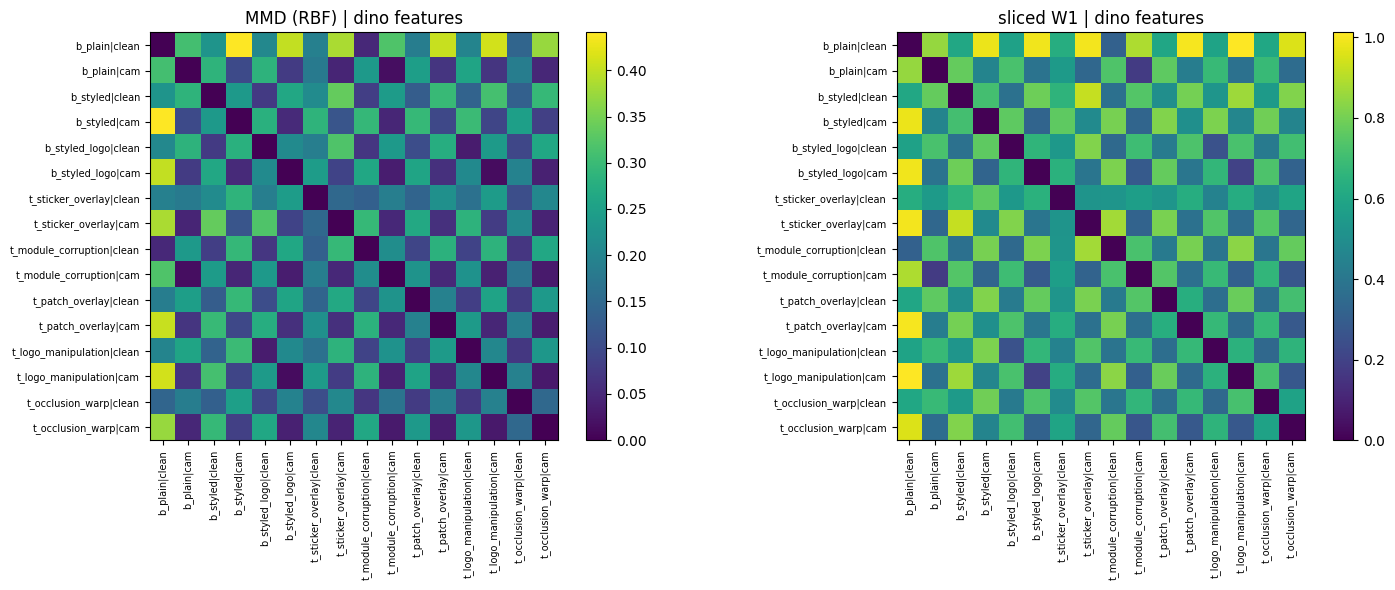

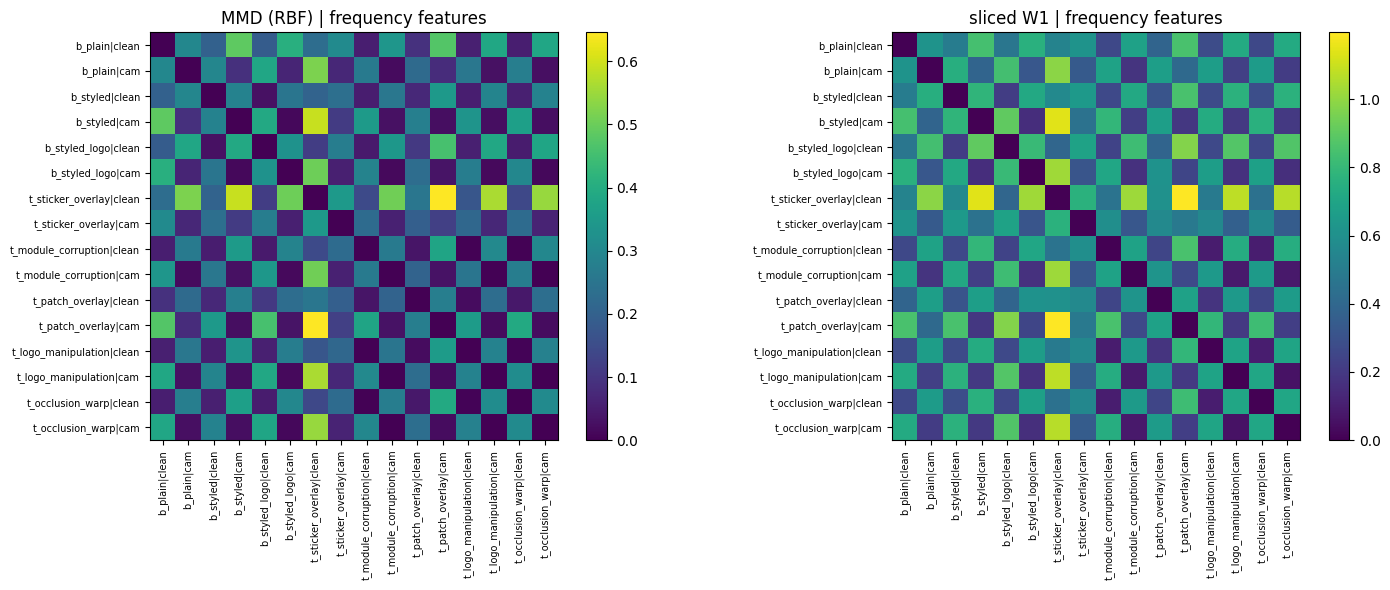

DINO-space MMD: plain vs styled benign = 0.2283 | plain clean vs plain camera = 0.3099


In [ ]:
# ── RQ4: pairwise distribution shift (HFP-SAM Fig. 5 uses W1 and MMD-RBF between datasets) ──────────
# Groups = QR class x (clean / camera layer), sampled from the TRAIN split. Distances are computed in standardised
# feature space. MMD: unbiased RBF-MMD^2 with the median heuristic. W1: sliced Wasserstein-1 (64 random projections).
import matplotlib.pyplot as plt
N_PER = 100 if SMOKE else 1000                          # images per group (MMD cost grows with N_PER squared)
CLASSES = ['benign_plain', 'benign_styled', 'benign_styled_logo'] + [f'tamper_{f}' for f in FAMILIES]
groups = {}
for c in CLASSES:
    for cond, mask in (('clean', ~tr.has_cam), ('cam', tr.has_cam)):
        d = tr[(tr.cls_ == c) & mask]
        if len(d) >= 10:
            groups[f'{c.replace("benign_", "b_").replace("tamper_", "t_")}|{cond}'] = d.sample(min(N_PER, len(d)), random_state=0).fidx.values

def rbf_mmd2(A, B, gamma):
    def k(X, Y):
        d2 = (X ** 2).sum(1)[:, None] + (Y ** 2).sum(1)[None] - 2 * X @ Y.T
        return np.exp(-gamma * np.maximum(d2, 0))
    Kaa, Kbb, Kab = k(A, A), k(B, B), k(A, B)
    n, m = len(A), len(B)
    return (Kaa.sum() - np.trace(Kaa)) / (n * (n - 1)) + (Kbb.sum() - np.trace(Kbb)) / (m * (m - 1)) - 2 * Kab.mean()

def shift_matrices(X, name):
    allidx = np.concatenate(list(groups.values()))
    mu, sd = X[allidx].mean(0), X[allidx].std(0) + 1e-6
    Z = {g: ((X[i] - mu) / sd).astype(np.float64) for g, i in groups.items()}
    pool = np.concatenate(list(Z.values()))
    sub = pool[np.random.default_rng(0).choice(len(pool), min(800, len(pool)), replace=False)]
    d2 = (sub ** 2).sum(1)[:, None] + (sub ** 2).sum(1)[None] - 2 * sub @ sub.T
    med = np.sqrt(np.median(d2[np.triu_indices(len(sub), 1)]))
    gamma = 1.0 / (2 * med ** 2)
    proj = np.random.default_rng(1).normal(size=(pool.shape[1], 64)); proj /= np.linalg.norm(proj, axis=0)
    names = list(Z)
    M = pd.DataFrame(np.nan, index=names, columns=names); W = M.copy()
    for a in names:
        for b in names:
            A, B = Z[a], Z[b]
            if len(A) > 2 and len(B) > 2:
                M.loc[a, b] = max(rbf_mmd2(A, B, gamma), 0.0)
                n = min(len(A), len(B))
                W.loc[a, b] = np.abs(np.sort(A[:n] @ proj, axis=0) - np.sort(B[:n] @ proj, axis=0)).mean()
    M.round(4).to_csv(TAB / f'rq4_mmd_{name}.csv'); W.round(4).to_csv(TAB / f'rq4_sw1_{name}.csv')
    fig, axs = plt.subplots(1, 2, figsize=(15, 6))
    for ax, mat, ttl in ((axs[0], M, 'MMD (RBF)'), (axs[1], W, 'sliced W1')):
        im = ax.imshow(mat.values.astype(float), cmap='viridis')
        ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=90, fontsize=7)
        ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=7)
        ax.set_title(f'{ttl} | {name} features'); plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.savefig(TAB / f'rq4_shift_{name}.png', dpi=160); plt.show()
    return M, W

M_d, W_d = shift_matrices(DINO_X, 'dino')
M_w, W_w = shift_matrices(np.concatenate([FREQ_X, WAV_X[:, WMULTI]], axis=1), 'frequency')
a, b, c = 'b_plain|clean', 'b_styled|clean', 'b_plain|cam'
if all(g in M_d.index for g in (a, b, c)):
    print(f'DINO-space MMD: plain vs styled benign = {M_d.loc[a, b]:.4f} | plain clean vs plain camera = {M_d.loc[a, c]:.4f}')

## RQ6: cross-domain transfer

In [ ]:
# ── RQ6: cross-domain transfer (HFP-SAM §I evaluates zero-shot transfer to unseen tasks) ──────────────
# T1: train on clean images only -> test on camera images (and the reverse).
# T2: train WITHOUT styled/logo benign codes -> AUROC and false-positive rate on styled/logo benign codes.
STYLED = ['benign_styled', 'benign_styled_logo']

def auc_(y, p):
    return roc_auc_score(y, p) if len(set(y)) > 1 else np.nan

rows = []
for sid in ['fft_global', 'wav_multi', 'canny_topk', 'dino_ref']:
    X = ALLSETS[sid] if sid in ALLSETS else SETS[sid]
    for seed in SEEDS:
        for tname, trf, vaf in [('all', tr, va), ('clean only', tr[~tr.has_cam], va[~va.has_cam]),
                                ('camera only', tr[tr.has_cam], va[va.has_cam]),
                                ('no styled benign', tr[~tr.cls_.isin(STYLED)], va[~va.cls_.isin(STYLED)])]:
            clf = make_clf2(sid, seed).fit(X[trf.fidx.values], trf.label.values)
            sc = lambda df: clf.predict_proba(X[df.fidx.values])[:, 1]
            th = pick_th(vaf.label.values, sc(vaf))
            tam = te[te.label == 1]
            tests = {'AUROC clean test': te[~te.has_cam], 'AUROC camera test': te[te.has_cam],
                     'AUROC plain-benign vs tamper': pd.concat([te[te.cls_ == 'benign_plain'], tam]),
                     'AUROC styled-benign vs tamper': pd.concat([te[te.cls_.isin(STYLED)], tam])}
            for k, df in tests.items():
                rows.append(dict(features=sid, trained_on=tname, metric=k, seed=seed, value=auc_(df.label.values, sc(df))))
            sty = te[te.cls_.isin(STYLED)]
            rows.append(dict(features=sid, trained_on=tname, metric='FPR on styled/logo benign', seed=seed,
                             value=float(np.mean(sc(sty) > th)) if len(sty) else np.nan))
T6 = pd.DataFrame(rows)
def _ms(x):
    x = x.dropna()
    return 'n/a' if not len(x) else (f'{x.mean():.3f} ± {x.std():.3f}' if len(x) > 1 else f'{x.mean():.3f}')
tab6 = T6.groupby(['features', 'trained_on', 'metric']).value.agg(_ms).unstack('metric')
print('=== RQ6: transfer. Compare "all" with "clean only"/"camera only" (camera effect) and "no styled benign" (benign-style effect) ===')
display(tab6)
tab6.to_csv(TAB / 'rq6_transfer.csv')

=== RQ6: transfer. Compare "all" with "clean only"/"camera only" (camera effect) and "no styled benign" (benign-style effect) ===


metric                      AUROC camera test AUROC clean test  \
features   trained_on                                            
canny_topk all                  0.626 ± 0.002    0.729 ± 0.002   
           camera only          0.602 ± 0.004    0.657 ± 0.004   
           clean only           0.590 ± 0.001    0.741 ± 0.002   
           no styled benign     0.558 ± 0.002    0.587 ± 0.001   
dino_ref   all                  0.940 ± 0.001    0.972 ± 0.001   
           camera only          0.940 ± 0.002    0.948 ± 0.005   
           clean only           0.561 ± 0.008    0.971 ± 0.001   
           no styled benign     0.689 ± 0.019    0.669 ± 0.001   
fft_global all                  0.754 ± 0.001    0.852 ± 0.000   
           camera only          0.754 ± 0.003    0.774 ± 0.001   
           clean only           0.626 ± 0.005    0.858 ± 0.003   
           no styled benign     0.614 ± 0.001    0.585 ± 0.001   
wav_multi  all                  0.677 ± 0.000    0.838 ± 0.002   
           camera only          0.689 ± 0.002    0.663 ± 0.006   
           clean only           0.542 ± 0.007    0.845 ± 0.001   
           no styled benign     0.590 ± 0.003    0.612 ± 0.000   

metric                      AUROC plain-benign vs tamper  \
features   trained_on                                      
canny_topk all                             0.683 ± 0.003   
           camera only                     0.599 ± 0.003   
           clean only                      0.665 ± 0.002   
           no styled benign                0.797 ± 0.002   
dino_ref   all                             0.957 ± 0.005   
           camera only                     0.942 ± 0.011   
           clean only                      0.759 ± 0.002   
           no styled benign                0.982 ± 0.001   
fft_global all                             0.835 ± 0.001   
           camera only                     0.771 ± 0.005   
           clean only                      0.765 ± 0.008   
           no styled benign                0.926 ± 0.001   
wav_multi  all                             0.819 ± 0.001   
           camera only                     0.723 ± 0.011   
           clean only                      0.778 ± 0.004   
           no styled benign                0.905 ± 0.001   

metric                      AUROC styled-benign vs tamper  \
features   trained_on                                       
canny_topk all                              0.686 ± 0.001   
           camera only                      0.655 ± 0.001   
           clean only                       0.678 ± 0.001   
           no styled benign                 0.424 ± 0.001   
dino_ref   all                              0.962 ± 0.000   
           camera only                      0.947 ± 0.002   
           clean only                       0.778 ± 0.001   
           no styled benign                 0.475 ± 0.011   
fft_global all                              0.806 ± 0.001   
           camera only                      0.761 ± 0.003   
           clean only                       0.701 ± 0.002   
           no styled benign                 0.382 ± 0.001   
wav_multi  all                              0.764 ± 0.002   
           camera only                      0.639 ± 0.008   
           clean only                       0.702 ± 0.005   
           no styled benign                 0.413 ± 0.002   

metric                      FPR on styled/logo benign  
features   trained_on                                  
canny_topk all                          0.263 ± 0.032  
           camera only                  0.282 ± 0.043  
           clean only                   0.378 ± 0.028  
           no styled benign             0.713 ± 0.018  
dino_ref   all                          0.038 ± 0.006  
           camera only                  0.059 ± 0.023  
           clean only                   0.381 ± 0.006  
           no styled benign             0.961 ± 0.005  
fft_global all                          0.184 ± 0.004  
           came

## How to use these results

* Report **what each experiment shows, including negative results**. For example, if global FFT features beat the wavelet-window features on some family, say so; the question here is *whether* a local frequency prior helps, not to show that it does.
* RQ1/RQ2 compare feature sets with the **same classifier and protocol**; RQ5 compares fusion modes with the same network and training budget. The 3-seed std measures classifier/training randomness only (the features and the split are fixed).
* RQ3 uses a single classifier seed for handcrafted features, and the noise scale (0–1 pixel range) is our choice.
* RQ4 distances are descriptive; they do not prove that shift *causes* a transfer failure (RQ6 is the empirical check).
* Everything is on synthetic images (no real-camera test set) and 224 × 224 inputs.

**Papers used (see the table at the top for exactly what was read):** HFP-SAM, arXiv 2603.12708; SFMFusion, arXiv 2511.06593; ISFM, arXiv 2602.04405.